# 02 - Modèle : taux de survie et de migration nette

Période : 1er janvier 2020 → 1er janvier 2025 (5 dernières années avec décès par âge, Eurostat s'arrêtant à 2024).

1. **Mortalité** par sexe et tranche : décès 2020-2024 / population moyenne.
2. **Table de mortalité abrégée** → rapport de survie sur 5 ans S(a) = L(a+5) / L(a) ; naissances → 0-4 : L(0-4)/5 ; tranche terminale : T(90)/T(85).
3. **Migration nette résiduelle** : M = P(2025, a+5) − S(a)·P(2020, a) ; taux = M / (S·P(2020, a)).

En projection : P(t+5, a+5) = S(a) · P(t, a) · (1 + taux_migration).

Hypothèses : naissances réparties 51,2 % garçons ; tranches INSEE 90-94 et 95+ fusionnées en 90+ ; population 2024-2025 provisoire.

In [1]:
import sys
sys.path.append('..')
import pandas as pd
pd.set_option('display.max_colwidth', 120)
import matplotlib.pyplot as plt
from src.chargement import charger_tout, PROCESSED_DIR
from src.taux import taux_survie_migration

tables = charger_tout()  # relit data/processed (lancer 01_donnees d'abord)
naissances = tables['dep3'].query("indicateur == 'naissances'").set_index('annee')['effectif']
taux = taux_survie_migration(tables['pop_aq'], tables['deces_age'], naissances, debut=2020, duree=5)
taux.to_csv(PROCESSED_DIR / 'taux_survie_migration_2020_2025.csv', index=False)

In [2]:
cols = ['sexe', 'tranche_depart', 'tranche_arrivee', 'taux_mortalite_annuel', 'taux_survie_5ans',
        'migration_nette_5ans', 'taux_migration_5ans', 'taux_migration_annuel']
taux[cols].style.format({'taux_mortalite_annuel': '{:.4f}', 'taux_survie_5ans': '{:.4f}',
                         'migration_nette_5ans': '{:+.0f}', 'taux_migration_5ans': '{:+.1%}',
                         'taux_migration_annuel': '{:+.2%}'}, na_rep='')

,sexe,tranche_depart,tranche_arrivee,taux_mortalite_annuel,taux_survie_5ans,migration_nette_5ans,taux_migration_5ans,taux_migration_annuel
0,Hommes,naissances,0-4,,0.9984,+481,+2.9%,+0.58%
1,Hommes,0-4,5-9,0.0006,0.9983,+2305,+12.5%,+2.39%
2,Hommes,5-9,10-14,0.0000,0.9997,+1051,+4.8%,+0.94%
3,Hommes,10-14,15-19,0.0001,0.9988,-338,-1.4%,-0.28%
4,Hommes,15-19,20-24,0.0004,0.9977,-4458,-18.8%,-4.07%
5,Hommes,20-24,25-29,0.0005,0.9966,+268,+1.5%,+0.29%
6,Hommes,25-29,30-34,0.0008,0.9943,+2786,+17.3%,+3.24%
7,Hommes,30-34,35-39,0.0014,0.9928,+2673,+14.1%,+2.67%
8,Hommes,35-39,40-44,0.0015,0.9903,+1988,+9.3%,+1.79%
9,Hommes,40-44,45-49,0.0024,0.9863,+1507,+7.1%,+1.38%


## Focus jeunes (arrivée en 15-19, 20-24, 25-29)

In [3]:
taux[taux.tranche_arrivee.isin(['15-19', '20-24', '25-29', '30-34'])][cols]

,sexe,tranche_depart,tranche_arrivee,taux_mortalite_annuel,taux_survie_5ans,migration_nette_5ans,taux_migration_5ans,taux_migration_annuel
3,Hommes,10-14,15-19,0.000067,0.998844,-338.336457,-0.014151,-0.002846
4,Hommes,15-19,20-24,0.000395,0.997683,-4457.803565,-0.187572,-0.040694
5,Hommes,20-24,25-29,0.000533,0.996571,268.081671,0.014623,0.002908
6,Hommes,25-29,30-34,0.000842,0.994319,2786.224668,0.172610,0.032359
22,Femmes,10-14,15-19,0.000098,0.999489,-1937.396061,-0.085373,-0.017689
23,Femmes,15-19,20-24,0.000107,0.999084,-5135.462193,-0.241108,-0.053684
24,Femmes,20-24,25-29,0.000260,0.998675,1723.467352,0.111685,0.021401
25,Femmes,25-29,30-34,0.000270,0.998256,3329.590990,0.210835,0.039003


In [4]:
# contrôle : survivants + migrants = population observée 2025
assert ((taux['survivants_attendus'] + taux['migration_nette_5ans'] - taux['effectif_arrivee']).abs() < 1e-6).all()
# contrôle : solde migratoire total vs solde apparent INSEE (variation - solde naturel) 2020-2024
d1 = tables['dep1'].pivot(index='annee', columns='indicateur', values='effectif').loc[2020:2024]
print('Migration nette (modèle) :', round(taux['migration_nette_5ans'].sum()))
print('Solde migratoire apparent INSEE :', round((d1['variation_totale'] - d1['solde_naturel']).sum()))

Migration nette (modèle) : 42587
Solde migratoire apparent INSEE : 43276


## Backtest : le modèle prévoit-il correctement ?

Calibrage des taux sur **2013 → 2018** (décès 2013-2017), projection d'un pas de 5 ans **2018 → 2023**, comparaison à la population estimée 2023. Naissances constantes = naissances 2013-2017.

Références :
- *survie seule* (sans migration) et *population figée* (P2023 = P2018) : le modèle doit faire mieux qu'elles ;
- *migration connue* : survie et naissances calibrées sur 2013-2018, mais **migration de 2018-2023**, comme si on la connaissait à l'avance. L'erreur restante ne vient alors que de la survie et des naissances : l'écart avec le modèle mesure le poids de l'hypothèse de migration.

In [5]:
from src.projection import backtest, erreurs, resume_erreurs
from src.graphiques import graphique_backtest

bt = backtest(tables['pop_aq'], tables['deces_age'], naissances, debut_calib=2013)
resume = resume_erreurs(bt)
resume.style.format('{:+.1%}')

,MAPE sexe x tranche,erreur max sexe x tranche,erreur population totale,erreur 15-29 ans
modele,+3.1%,+10.7%,-2.1%,-4.8%
migration_connue,+0.9%,+8.2%,+0.2%,-0.0%
sans_migration,+7.4%,+22.3%,-4.8%,+7.2%
population_figee,+7.5%,+27.9%,-3.6%,-4.4%


In [6]:
e = resume['erreur 15-29 ans']
print(f"Erreur sur les 15-29 ans en 2023 : {e['modele']:+.1%} avec la migration 2013-2018 ; "
      f"avec la migration de 2018-2023 connue à l'avance, l'erreur serait de {e['migration_connue']:+.2%}.")

Erreur sur les 15-29 ans en 2023 : -4.8% avec la migration 2013-2018 ; avec la migration de 2018-2023 connue à l'avance, l'erreur serait de -0.03%.


In [7]:
err = erreurs(bt)
err.to_csv(PROCESSED_DIR / 'backtest_2018_2023_erreurs.csv')
err[['reel', 'modele', 'err_modele', 'err_rel_modele', 'err_rel_migration_connue',
     'err_rel_sans_migration', 'err_rel_population_figee']].style.format(
    {'reel': '{:,.0f}', 'modele': '{:,.0f}', 'err_modele': '{:+,.0f}', 'err_rel_modele': '{:+.1%}',
     'err_rel_migration_connue': '{:+.1%}', 'err_rel_sans_migration': '{:+.1%}',
     'err_rel_population_figee': '{:+.1%}'})

,reel,modele,err_modele,err_rel_modele,err_rel_migration_connue,err_rel_sans_migration,err_rel_population_figee
tranche_age,,,,,,,
0-4,"34,368","36,675","+2,307",+6.7%,+8.2%,+4.7%,+6.7%
5-9,"40,829","39,874",-955,-2.3%,-0.0%,-10.3%,+8.2%
10-14,"46,185","45,727",-458,-1.0%,+0.0%,-4.4%,+0.2%
15-19,"43,379","43,020",-359,-0.8%,+0.0%,+6.6%,-0.8%
20-24,"35,858","34,331","-1,527",-4.3%,-0.0%,+19.8%,-10.3%
25-29,"33,828","30,294","-3,534",-10.4%,-0.1%,-5.2%,-2.7%
30-34,"38,270","35,662","-2,608",-6.8%,-0.0%,-14.3%,+1.7%
35-39,"43,188","41,445","-1,743",-4.0%,-0.0%,-10.3%,+1.1%
40-44,"47,218","45,365","-1,853",-3.9%,+0.0%,-8.2%,-3.1%


In [8]:
# jeunes, par sexe
par_sexe = erreurs(bt.assign(groupe=bt.sexe + ' ' + bt.tranche_age), par='groupe')
par_sexe.loc[[f'{s} {t}' for s in ('Hommes', 'Femmes') for t in ('15-19', '20-24', '25-29')],
             ['reel', 'modele', 'err_rel_modele', 'err_rel_migration_connue', 'err_rel_population_figee']].style.format(
    {'reel': '{:,.0f}', 'modele': '{:,.0f}', 'err_rel_modele': '{:+.1%}', 'err_rel_migration_connue': '{:+.1%}',
     'err_rel_population_figee': '{:+.1%}'})

,reel,modele,err_rel_modele,err_rel_migration_connue,err_rel_population_figee
groupe,,,,,
Hommes 15-19,"23,140","22,545",-2.6%,+0.0%,-1.4%
Hommes 20-24,"19,344","18,866",-2.5%,-0.0%,-10.5%
Hommes 25-29,"17,487","15,612",-10.7%,-0.1%,-4.4%
Femmes 15-19,"20,239","20,475",+1.2%,+0.0%,-0.1%
Femmes 20-24,"16,514","15,465",-6.4%,-0.0%,-10.0%
Femmes 25-29,"16,341","14,682",-10.2%,-0.1%,-0.8%


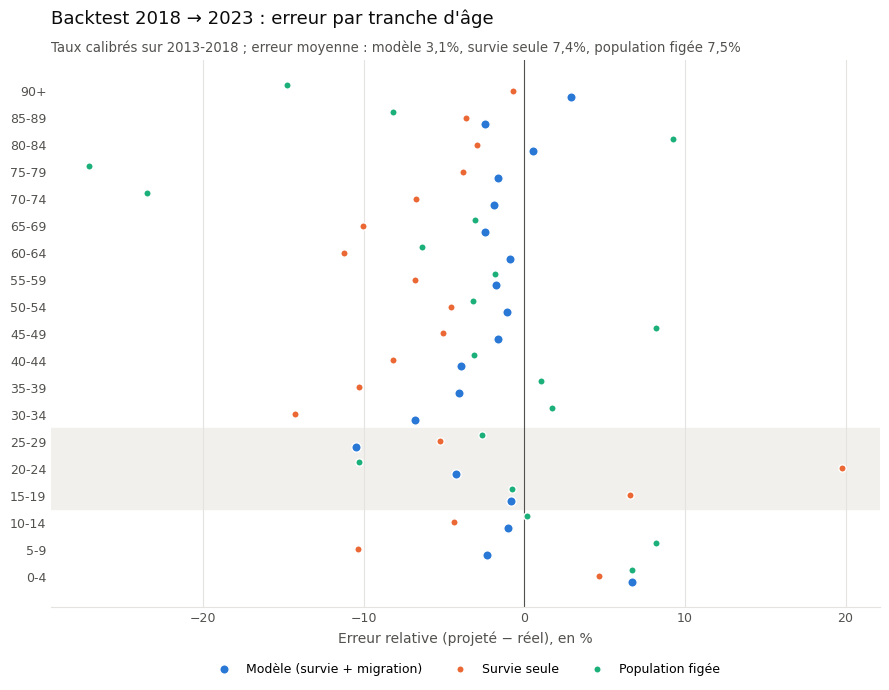

In [9]:
mape = resume['MAPE sexe x tranche'].map(lambda x: f'{x:.1%}'.replace('.', ','))
sous_titre = (f"Taux calibrés sur 2013-2018 ; erreur moyenne : modèle {mape['modele']}, "
              f"survie seule {mape['sans_migration']}, population figée {mape['population_figee']}")
fig, ax = graphique_backtest(err, "Backtest 2018 → 2023 : erreur par tranche d'âge", sous_titre)
fig.savefig('../figures/backtest_2018_2023.png', dpi=150, bbox_inches='tight')

**Lecture.**
- Le modèle divise par plus de deux l'erreur moyenne des références naïves.
- Il **sous-estime** la plupart des tranches en 2023, car le solde migratoire du Morbihan a fortement augmenté entre la période de calibrage (2013-2018 : +21 000) et la période projetée (2018-2023 : +39 000).
- Avec la migration de 2018-2023 connue à l'avance, l'erreur sur les 15-29 ans devient quasi nulle : **la migration est le facteur dominant**. C'est elle qu'il faut faire varier dans les scénarios ; survie et naissances (pour les 15-29 ans) pèsent peu.
- Sur le total des 15-29 ans, le modèle ne fait pas mieux que la population figée (≈ −4 à −5 %).
- La tranche 0-4 est surestimée car les naissances, supposées constantes, ont baissé.